<a href="https://colab.research.google.com/github/fdac25/MP2/blob/main/Vis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
import pandas as pd
import matplotlib.pyplot as plt



In [54]:
df = pd.read_csv("asangiul_project_summary.csv", sep=";")
df.columns = ['project','commit','author','time','message']
df['Month'] = pd.to_datetime(df['time'], unit='s').dt.strftime('%Y-%m')
df.head()

,project,commit,author,time,message,Month
0,pmelchior_scarlet,002d22cec20062a7451e0ad9eb1bd6d16340b152,herjy <remy.joseph11@gmail.com>,1588732939,multiresolution notebook reduced runtime\n,2020-05
1,pmelchior_scarlet,00432a5b4304ce4798bcd862428ce7d652413695,fred3m <fredem@princeton.edu>,1592232267,Ignore pycharm files\n,2020-06
2,pmelchior_scarlet,0061ee0346e18a457e9c5144bc2c211f8f028010,Peter Melchior <peter.m.melchior@gmail.com>,1509552506,renamed package; adjusted imports in init\n,2017-11
3,pmelchior_scarlet,0071ff32459cb8df3ebe0b85888ad155fd4e2bdb,Peter Melchior <peter.m.melchior@gmail.com>,1597436573,bugfixes; reduced point source center step to ...,2020-08
4,pmelchior_scarlet,00870ab9c2ada553172b83d60dcb74c50bcbe80f,fred3m <fredem@princeton.edu>,1620142667,Update starlet classes and function with new w...,2021-05


In [55]:
prj='openintrostat_openintro-r-package'
df1 = df[df['project']==prj]
df2 = df1.groupby('Month').size().reset_index(name='Commits')
monthly_counts = df2
monthly_counts['time'] = pd.to_datetime(monthly_counts['Month'])
full_date_range = pd.DataFrame({'time': pd.date_range(start=monthly_counts['time'].min(), end=monthly_counts['time'].max(), freq='MS')})
monthly_counts = pd.merge(full_date_range, monthly_counts, on='time', how='left').fillna(0)
monthly_counts['Month'] = monthly_counts['time'].dt.strftime('%Y-%m')

out = monthly_counts[['Month','Commits']].rename(columns={'Commits':'#Commits'})
out['#Commits'] = out['#Commits'].astype(int)
out.to_csv('asangiul_commits_timeseries.csv', sep=';', index=False)


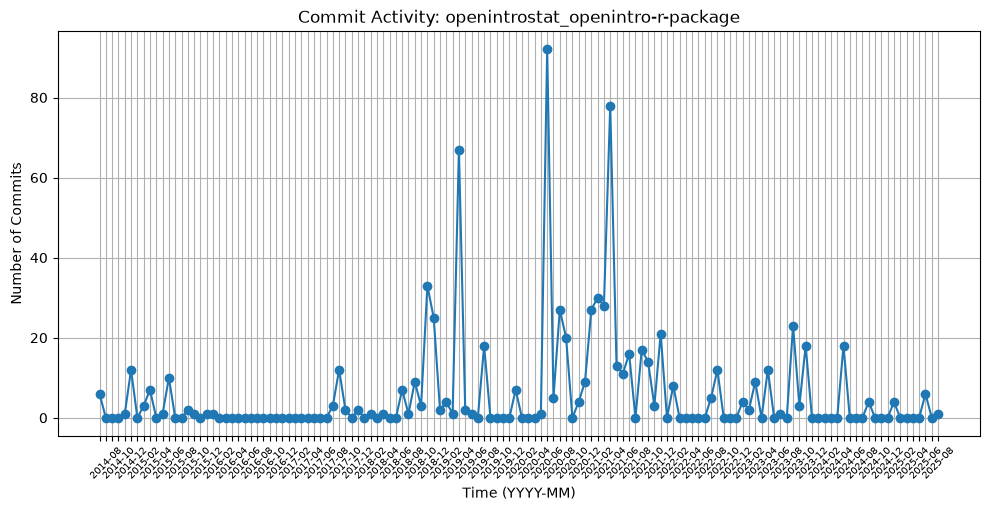

In [56]:
# Plot
import matplotlib.ticker as ticker

plt.figure(figsize=(10,5))
plt.plot(monthly_counts["Month"], monthly_counts["Commits"], marker="o", linestyle="-")
plt.xlabel("Time (YYYY-MM)")
plt.ylabel("Number of Commits")
plt.title("Commit Activity: "+prj)
plt.grid(True)
plt.tight_layout()
ax =  plt.gca()
for label in ax.xaxis.get_ticklabels()[::2]:
    label.set_visible(False)
plt.xticks(rotation=45, fontsize=7)
plt.savefig("asangiul_timeseries_"+prj+".png", dpi=600)
plt.show()
plt.close()

# Identify the Longest Inactivity Gap

2022-02 to 2023-04

Add all that info to netid_project_stats.csv